---
title: "Issued 1 November 2023: the next six months"
subtitle: "Monthly rainfall forecasts for Indonesia from one CFSv2 start, December 2023 to May 2024, calibrated with CCA and PCR"
description: "Download CFSv2 started on 1 November 2023, build CHIRPS v3.0 monthly totals from dekads for each of the next six months, fit CCA and PCR at each lead with PyCPT, score the hindcasts and the forecasts as issued, and compare with forecasting one month from earlier starts."
execute:
  enabled: false
---

A forecast centre issues an outlook on one date and looks several months ahead.
This notebook does exactly that: it takes the CFSv2 run started on **1 November
2023** and makes a calibrated forecast for each of the next six months, from
December 2023 to May 2024. Lead 1 is the month starting one month after the issue
date, lead 6 the one starting six months after it.

Because each lead is a different calendar month, a change in skill from one
lead to the next mixes two things: forecasting further ahead, and some months
being easier to forecast than others. Section 6 separates them by doing the
opposite as well: one target, November 2023, forecast from six earlier starts.

::: {.callout-note title="What you need to run this page"}
The full PyCPT environment with its CPT engine, internet access the first time
(CFSv2 files from the IRI Data Library, no key needed), and the CHIRPS v3.0
dekadal archive described in step 2. Eighteen fits take several minutes; times are
printed below.
:::

## 1. One issue date, six targets

The **lead** is the number of whole months between the issue date and the first
day of the target. PyCPT counts each target month from the start to its middle,
so its own leads are half a month larger (months of three months span three
PyCPT leads). Training uses the **target** years 1991-2020, as PyCPT's
`target_first_year` and `target_final_year` define them: for a target in
January or later, the 1 November starts are those of the year before. The cell asks
PyCPT for both.

In [1]:
from pathlib import Path
import datetime as dt
import json
import re
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
import xarray as xr
import cartopy.io.shapereader as shapereader
import cptdl as dl
import pycpt
from pycpt import notebook as pycpt_notebook

repo = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pycpt_tutorial").is_dir()), None)
if repo is None:
    raise FileNotFoundError("Run this notebook inside the tutorial repository or kit.")
sys.path.insert(0, str(repo))
from pycpt_tutorial.country_grid import aggregate_country_rainfall, training_complete_mask
from pycpt_tutorial.export import save_netcdf
from pycpt_tutorial import checks, figures
figures.use_style()

predictor_names = ["CFSv2.PRCP"]
predictand_name = "CHIRPS3.PRCP"
issue = dt.datetime(2023, 11, 1)
leads = [1, 2, 3, 4, 5, 6]                       # months from the issue date to the first day of the target
target_length = 1                          # months in each target
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
targets = {lead: f"{MONTHS[(issue.month - 1 + lead) % 12]}-{MONTHS[(issue.month - 2 + lead + target_length) % 12]}"
           for lead in leads}
predictor_extent = {"west": 85, "east": 155, "south": -20, "north": 20}
predictand_extent = {"west": 94, "east": 142, "south": -12, "north": 7}
training_years = list(range(1991, 2021))          # target years
cpt_args = {
    "transform_predictand": None,
    "tailoring": None,
    "cca_modes": (2, 2),
    "x_eof_modes": (3, 3),
    "y_eof_modes": (3, 3),
    "validation": "crossvalidation",
    "drymask_threshold": None,
    "skillmask_threshold": None,
    "crossvalidation_window": 5,
    "synchronous_predictors": True,
}
force_download = False
case_root = Path.home() / "PyCPT" / "indonesia-issued-2023-11-months"

# Section 7: one target forecast from six earlier starts (the design of the earlier version of this case)
fixed_target = "Nov-Nov"
fixed_starts = {lead: dt.datetime(2023, 11 - lead, 1) for lead in leads}
fixed_root = Path.home() / "PyCPT" / "indonesia-nov-2023-leads"

rows = []
for lead, target in targets.items():
    low, high = dl.leads_from_target(issue, target)
    delta = pycpt_notebook.issue_year_delta(issue.month, target)
    rows.append({"lead (months)": lead, "target": target, "PyCPT lead": f"{low} to {high}",
                 "hindcast starts": f"1 Nov {training_years[0] + delta}-{training_years[-1] + delta}",
                 "2023 start": issue.strftime("%d %b %Y")})
pd.DataFrame(rows).set_index("lead (months)")

,target,PyCPT lead,hindcast starts,2023 start
lead (months),,,,
1,Dec-Dec,1.5 to 1.5,1 Nov 1991-2020,01 Nov 2023
2,Jan-Jan,2.5 to 2.5,1 Nov 1990-2019,01 Nov 2023
3,Feb-Feb,3.5 to 3.5,1 Nov 1990-2019,01 Nov 2023
4,Mar-Mar,4.5 to 4.5,1 Nov 1990-2019,01 Nov 2023
5,Apr-Apr,5.5 to 5.5,1 Nov 1990-2019,01 Nov 2023
6,May-May,6.5 to 6.5,1 Nov 1990-2019,01 Nov 2023


## 2. Observations from dekads

The predictand is CHIRPS v3.0 rainfall from the local **dekadal** archive (three
accumulation periods per month: days 1-10, 11-20 and 21 to the end), the same
archive family as [chapter 3](../learn/03-local-observations.ipynb). Its metadata
says exact zeros are kept. A target total is the sum of the dekads that tile it.
The function below finds them from the stored time bounds and refuses to sum
unless they run contiguously from the target's first day to the day after its last.

In [2]:
chirps3_file = Path("/mnt/e/temp/chirps/dekad/wld_cli_chirps3_dekad_1981_2025.nc")
source = xr.open_dataset(chirps3_file)
print("Variable attributes:", {k: source.precip.attrs[k] for k in ("units", "cell_methods", "comment")})
bounds = pd.DatetimeIndex(source.time_bnds.values.ravel()).values.reshape(-1, 2)
dekad_first, dekad_end = pd.DatetimeIndex(bounds[:, 0]), pd.DatetimeIndex(bounds[:, 1])
print(f"Dekads in the archive: {len(dekad_first)}, {dekad_first[0]:%d %b %Y} to {dekad_end[-1]:%d %b %Y}")
box = predictand_extent
region = source.precip.sel(lon=slice(box["west"], box["east"]), lat=slice(box["south"], box["north"]))


def period_total(first, last):
    # Sum of the dekads covering first..last (inclusive days), checked against the stored bounds.
    end = pd.Timestamp(last) + pd.Timedelta(days=1)
    index = np.flatnonzero((dekad_first >= pd.Timestamp(first)) & (dekad_end <= end))
    assert len(index) > 0 and dekad_first[index[0]] == pd.Timestamp(first) and dekad_end[index[-1]] == end, (first, last)
    assert (dekad_first[index[1:]] == dekad_end[index[:-1]]).all(), (first, last)
    return region.isel(time=index).sum("time", skipna=False)

Variable attributes: {'units': 'mm', 'cell_methods': 'time: sum', 'comment': 'Exact zeros are preserved, for a zero-inflated distribution fit. NaN marks no data.'}
Dekads in the archive: 1620, 01 Jan 1981 to 01 Jan 2026


A consistency check against a separately stored product: the archive also has
3-month totals (the file chapter 3 used). December-February built from nine dekads
should equal the stored total. The cell compares them for the first training season
and for the 2023-24 season.

In [3]:
rolling = xr.open_dataset("/mnt/e/temp/chirps/rolling_dekad/wld_cli_chirps3_month3_bydekad_1981_2025.nc")
rolling_first = pd.DatetimeIndex(rolling.time_bnds.values[:, 0])
rolling_end = pd.DatetimeIndex(rolling.time_bnds.values[:, 1])
for year in [1990, 2023]:
    first, last = pd.Timestamp(year, 12, 1), pd.Timestamp(year + 1, 2, 1) + pd.offsets.MonthEnd(0)
    k = int(np.flatnonzero((rolling_first == first) & (rolling_end == last + pd.Timedelta(days=1)))[0])
    stored = rolling.precip.sel(lon=slice(box["west"], box["east"]), lat=slice(box["south"], box["north"])).isel(time=k).load()
    from_dekads = period_total(first, last).load()
    gap = abs(from_dekads - stored)
    print(f"DJF {year}-{(year + 1) % 100:02d} ({first:%d %b %Y} to {last:%d %b %Y}): largest difference {float(gap.max()):.4f} mm, "
          f"same missing pixels: {bool((from_dekads.isnull() == stored.isnull()).all())}")

DJF 1990-91 (01 Dec 1990 to 28 Feb 1991): largest difference 0.0002 mm, same missing pixels: True


DJF 2023-24 (01 Dec 2023 to 29 Feb 2024): largest difference 0.0005 mm, same missing pixels: True


The 0.25° grid and the Indonesia land rule are the ones from chapter 3: a cell is
the cosine-latitude weighted mean of the Indonesian 0.05° pixels inside it, kept
only when at least 99% of its country-land weight has data. A cell enters the fits
only if it has data in all 30 training years **of every target used on this page**
(the six leads and the November target of section 7), so every area mean
covers the same cells.

In [4]:
records = shapereader.Reader(shapereader.natural_earth("10m", "cultural", "admin_0_countries")).records()
indonesia = next(r.geometry for r in records if r.attributes["ADM0_A3"] == "IDN")
shapely.prepare(indonesia)
lon2d, lat2d = np.meshgrid(region.lon, region.lat)
country = xr.DataArray(shapely.contains_xy(indonesia, lon2d, lat2d), dims=("lat", "lon"),
                       coords={"lat": region.lat, "lon": region.lon})
print(f"Native pixels inside Indonesia: {int(country.sum()):,}")
centres_y = box["south"] + 0.125 + np.arange(76) * 0.25
centres_x = box["west"] + 0.125 + np.arange(192) * 0.25


def observed_cells(data):
    # Target totals on the 0.25 degree grid for the T, Ti, Tf axis of a PyCPT file.
    native = xr.concat([period_total(a, b) for a, b in zip(data["Ti"].values, data["Tf"].values)],
                       dim=pd.Index(data["T"].values, name="T")).load()
    zeros = int(((native == 0) & country).sum())
    cells = aggregate_country_rainfall(native, country, 5, minimum_coverage=0.99).precipitation
    cells = cells.rename({"lat": "Y", "lon": "X"}).assign_coords(Y=centres_y, X=centres_x).sortby("Y", ascending=False)
    return cells.assign_coords(Ti=("T", data["Ti"].values), Tf=("T", data["Tf"].values)), zeros

Native pixels inside Indonesia: 61,192


## 3. One case folder per lead

Each lead is its own forecast question, so each gets its own case folder
([chapter 7](../learn/07-adapt-your-region.ipynb) explains why folders should not
be shared between questions). The hindcasts are downloaded first, because their
`T`, `Ti` and `Tf` say exactly which days each training target covers; the
observations are then built for those days and saved as that folder's local
predictand file. The November starts of section 7 are prepared the same way.

In [5]:
def prepare(name, args, folder):
    domain_dir = pycpt.setup(folder, predictor_extent)
    hindcasts = pycpt_notebook.download_hindcasts(predictor_names, domain_dir, force_download, args)[0]
    assert (pd.DatetimeIndex(hindcasts["T"].values).year == np.array(training_years)).all()
    Yl, zeros = observed_cells(hindcasts)
    return dict(name=name, args=args, domain_dir=domain_dir, folder=folder, Y_all=Yl, zeros=zeros,
                complete=training_complete_mask(Yl, training_years))


start = time.monotonic()
questions = {}
for lead, target in targets.items():
    args = dict(fdate=issue, target=target, target_first_year=training_years[0], target_final_year=training_years[-1],
                predictor_extent=predictor_extent, predictand_extent=predictand_extent)
    questions["issue", lead] = prepare(target, args, case_root / f"lead-{lead}")
for lead, fdate in fixed_starts.items():
    args = dict(fdate=fdate, target=fixed_target, target_first_year=training_years[0], target_final_year=training_years[-1],
                predictor_extent=predictor_extent, predictand_extent=predictand_extent)
    questions["fixed", lead] = prepare(fixed_target, args, fixed_root / f"lead-{lead}")
cells = xr.concat([q["complete"] for q in questions.values()], "q").all("q")
print(f"Hindcast axes and observations for {len(questions)} questions in {time.monotonic() - start:.0f} s")
print(f"Cells complete in all 30 training years of every target: {int(cells.sum())} "
      f"(per target: {sorted({int(q['complete'].sum()) for q in questions.values()})})")
print("Indonesian native pixel-targets at exactly 0 mm, by lead:",
      {lead: questions["issue", lead]["zeros"] for lead in leads})

Input data will be saved in ~/PyCPT/indonesia-issued-2023-11-months/lead-1/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-issued-2023-11-months/lead-1/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-issued-2023-11-months/lead-1/85W-155E_to_-20S-20N/output
URL: https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/S/%280000%201%20Nov%201991-2020%29/VALUES/L/1.5/1.5/RANGEEDGES/%5BL%5D//keepgrids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/31/mul/-999/setmissing_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv


DOWNLOADING: [*************************] (1271 KB) 0:00:04.719758


Input data will be saved in ~/PyCPT/indonesia-issued-2023-11-months/lead-2/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-issued-2023-11-months/lead-2/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-issued-2023-11-months/lead-2/85W-155E_to_-20S-20N/output
URL: https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/S/%280000%201%20Nov%201990-2019%29/VALUES/L/2.5/2.5/RANGEEDGES/%5BL%5D//keepgrids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/31/mul/-999/setmissing_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv


DOWNLOADING: [*************************] (1277 KB) 0:00:04.201845


Input data will be saved in ~/PyCPT/indonesia-issued-2023-11-months/lead-3/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-issued-2023-11-months/lead-3/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-issued-2023-11-months/lead-3/85W-155E_to_-20S-20N/output
URL: https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/S/%280000%201%20Nov%201990-2019%29/VALUES/L/3.5/3.5/RANGEEDGES/%5BL%5D//keepgrids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/28.25/mul/-999/setmissing_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv


DOWNLOADING: [*************************] (1261 KB) 0:00:01.993823


... (9 outputs left out)

Input data will be saved in ~/PyCPT/indonesia-nov-2023-leads/lead-4/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-nov-2023-leads/lead-4/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-nov-2023-leads/lead-4/85W-155E_to_-20S-20N/output
Reusing already-downloaded CFSv2.PRCP



Input data will be saved in ~/PyCPT/indonesia-nov-2023-leads/lead-5/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-nov-2023-leads/lead-5/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-nov-2023-leads/lead-5/85W-155E_to_-20S-20N/output
Reusing already-downloaded CFSv2.PRCP



Input data will be saved in ~/PyCPT/indonesia-nov-2023-leads/lead-6/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-nov-2023-leads/lead-6/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-nov-2023-leads/lead-6/85W-155E_to_-20S-20N/output
Reusing already-downloaded CFSv2.PRCP



Hindcast axes and observations for 12 questions in 207 s
Cells complete in all 30 training years of every target: 3240 (per target: [3240])
Indonesian native pixel-targets at exactly 0 mm, by lead: {1: 97, 2: 147, 3: 841, 4: 500, 5: 447, 6: 80}


In [6]:
inputs, rows, warnings = {}, [], set()
for key, q in questions.items():
    Yl = q["Y_all"].where(cells).transpose("T", "Y", "X").rename("precipitation")
    Yl.attrs = {"units": "mm", "missing": -999.0,
                "long_name": f"CHIRPS v3.0 {q['name']} rainfall total, Indonesia land, 0.25 degree"}
    local_file = q["folder"] / f"local-CHIRPS3-{q['name']}-1991-2020.nc"
    save_netcdf(Yl.to_dataset(), local_file, overwrite=True,
                metadata={"source_file": chirps3_file.name,
                          "aggregation": "sum of the dekads tiling each target; cos-latitude weighted mean of Indonesian 0.05 degree pixels per 0.25 degree cell; at least 99% country-land coverage",
                          "boundary": "Natural Earth 1:10m admin_0_countries, ADM0_A3=IDN",
                          "training_years": "target years 1991-2020"})
    checks.remember_question(q["args"], q["domain_dir"])
    Yd, X, F = pycpt.download_data(predictand_name, local_file, predictor_names, q["args"], q["domain_dir"], force_download)
    same_axis = bool((X[0]["T"].values == Yl["T"].values).all() and (X[0]["Ti"].values == Yl["Ti"].values).all()
                     and (X[0]["Tf"].values == Yl["Tf"].values).all())
    table = checks.check_case(q["args"], predictand_name, Yd, X, F, predictor_names, q["domain_dir"])
    warnings |= {f"{r.check}: {r.detail}" for r in table.itertuples() if r.status == "warn"}
    inputs[key] = dict(q, Y=Yd, Yl=Yl, X=X, F=F)
    s0, f0 = pd.Timestamp(X[0]["S"].values[0]), pd.Timestamp(F[0]["S"].values[0])
    rows.append({"design": key[0], "lead": key[1], "target": q["name"],
                 "hindcast starts": f"{s0:%d %b} {s0.year}-{pd.Timestamp(X[0]['S'].values[-1]).year}",
                 "training targets": f"{pd.Timestamp(Yl['Ti'].values[0]):%d %b %Y} ... {pd.Timestamp(Yl['Tf'].values[-1]):%d %b %Y}",
                 "forecast start": f"{f0:%d %b %Y}",
                 "forecast target": f"{pd.Timestamp(F[0]['Ti'].values[0]):%d %b %Y} to {pd.Timestamp(F[0]['Tf'].values[0]):%d %b %Y}",
                 "same T, Ti, Tf as Y": same_axis, "preflight": checks.summary(table)})
print("Preflight warnings (all questions):", *sorted(warnings), sep="\n  ")
pd.DataFrame(rows).set_index(["design", "lead"])

URL: https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/S/%280000%201%20Nov%202023%29/VALUES/L/1.5/1.5/RANGEEDGES/%5BL%5D//keepgrids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/31/mul/-999/setmissing_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv


DOWNLOADING: [*************************] (44 KB) 0:00:00.515788

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP

URL: https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/S/%280000%201%20Nov%202023%29/VALUES/L/2.5/2.5/RANGEEDGES/%5BL%5D//keepgrids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/31/mul/-999/setmissing_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv


DOWNLOADING: [*************************] (43 KB) 0:00:00.511229

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP

URL: https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/S/%280000%201%20Nov%202023%29/VALUES/L/3.5/3.5/RANGEEDGES/%5BL%5D//keepgrids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/28.25/mul/-999/setmissing_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv


DOWNLOADING: [*************************] (44 KB) 0:00:00.511622

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP

URL: https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/S/%280000%201%20Nov%202023%29/VALUES/L/4.5/4.5/RANGEEDGES/%5BL%5D//keepgrids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/31/mul/-999/setmissing_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv


DOWNLOADING: [*************************] (44 KB) 0:00:00.510802

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP

URL: https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/S/%280000%201%20Nov%202023%29/VALUES/L/5.5/5.5/RANGEEDGES/%5BL%5D//keepgrids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/30/mul/-999/setmissing_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv


DOWNLOADING: [*************************] (43 KB) 0:00:00.745761

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP

URL: https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/S/%280000%201%20Nov%202023%29/VALUES/L/6.5/6.5/RANGEEDGES/%5BL%5D//keepgrids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/31/mul/-999/setmissing_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv


... (2 outputs left out)

Reusing already-downloaded CFSv2.PRCP_f2023

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP

Reusing already-downloaded CFSv2.PRCP_f2023

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP



Reusing already-downloaded CFSv2.PRCP_f2023

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP

Reusing already-downloaded CFSv2.PRCP_f2023

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP



Preflight warnings (all questions):
  CFSv2.PRCP: units label: units attribute is 'mm/day', a rate; the catalog requests examined in chapter 1 multiply by the season length, so confirm whether the values are rates or seasonal totals.


target   hindcast starts             training targets  \
design lead                                                           
issue  1     Dec-Dec  01 Nov 1991-2020  01 Dec 1991 ... 31 Dec 2020   
       2     Jan-Jan  01 Nov 1990-2019  01 Jan 1991 ... 31 Jan 2020   
       3     Feb-Feb  01 Nov 1990-2019  01 Feb 1991 ... 29 Feb 2020   
       4     Mar-Mar  01 Nov 1990-2019  01 Mar 1991 ... 31 Mar 2020   
       5     Apr-Apr  01 Nov 1990-2019  01 Apr 1991 ... 30 Apr 2020   
       6     May-May  01 Nov 1990-2019  01 May 1991 ... 31 May 2020   
fixed  1     Nov-Nov  01 Oct 1991-2020  01 Nov 1991 ... 30 Nov 2020   
       2     Nov-Nov  01 Sep 1991-2020  01 Nov 1991 ... 30 Nov 2020   
       3     Nov-Nov  01 Aug 1991-2020  01 Nov 1991 ... 30 Nov 2020   
       4     Nov-Nov  01 Jul 1991-2020  01 Nov 1991 ... 30 Nov 2020   
       5     Nov-Nov  01 Jun 1991-2020  01 Nov 1991 ... 30 Nov 2020   
       6     Nov-Nov  01 May 1991-2020  01 Nov 1991 ... 30 Nov 2020   

            forecast start             forecast target  same T, Ti, Tf as Y  \
design lead                                                                   
issue  1       01 Nov 2023  01 Dec 2023 to 31 Dec 2023                 True   
       2       01 Nov 2023  01 Jan 2024 to 31 Jan 2024                 True   
       3       01 Nov 2023  01 Feb 2024 to 29 Feb 2024                 True   
       4       01 Nov 2023  01 Mar 2024 to 31 Mar 2024                 True   
       5       01 Nov 2023  01 Apr 2024 to 30 Apr 2024                 True   
       6       01 Nov 2023  01 May 2024 to 31 May 2024                 True   
fixed  1       01 Oct 2023  01 Nov 2023 to 30 Nov 2023                 True   
       2       01 Sep 2023  01 Nov 2023 to 30 Nov 2023                 True   
       3       01 Aug 2023  01 Nov 2023 to 30 Nov 2023                 True   
       4       01 Jul 2023  01 Nov 2023 to 30 Nov 2023                 True   
       5       01 Jun 2023  01 Nov 2023 to 30 Nov 2023                 True   
       6       01 May 2023  01 Nov 2023 to 30 Nov 2023                 True   

                                    preflight  
design lead                                    
issue  1     {'ok': 10, 'warn': 1, 'fail': 0}  
       2     {'ok': 10, 'warn': 1, 'fail': 0}  
       3     {'ok': 10, 'warn': 1, 'fail': 0}  
       4     {'ok': 10, 'warn': 1, 'fail': 0}  
       5     {'ok': 10, 'warn': 1, 'fail': 0}  
       6     {'ok': 10, 'warn': 1, 'fail': 0}  
fixed  1     {'ok': 10, 'warn': 1, 'fail': 0}  
       2     {'ok': 10, 'warn': 1, 'fail': 0}  
       3     {'ok': 10, 'warn': 1, 'fail': 0}  
       4     {'ok': 10, 'warn': 1, 'fail': 0}  
       5     {'ok': 10, 'warn': 1, 'fail': 0}  
       6     {'ok': 10, 'warn': 1, 'fail': 0}

Units: the downloaded files say `mm/day`, but each request multiplies the daily
mean by the number of days in the target (the `/mul` step in PyCPT's request), so
the values are totals in millimetres, as
[chapter 2](../learn/02-getting-data.ipynb) found. PyCPT's month lengths give
February 28.25 days in every year (`monthlengths` in `cptdl/targetleadconv.py`),
while the observations have 28 or 29. Regression onto the observed totals absorbs a
constant factor, and correlation ignores it. The cell reads the factor from each
request and compares the hindcasts' 1991-2020 mean with the observed mean.

In [7]:
weights = np.cos(np.deg2rad(cells["Y"])) * cells
rows = []
for lead in leads:
    d = inputs["issue", lead]
    url = dl.evaluate_url(dl.hindcasts[predictor_names[0]], **pycpt_notebook._preprocess_download_args(d["args"]))
    X = d["X"][0]
    X = X.where((X > -999) & (X["X"] >= box["west"]) & (X["X"] <= box["east"]) & (X["Y"] >= box["south"]) & (X["Y"] <= box["north"]))
    rows.append({"lead": lead, "target": d["name"], "units attribute": d["X"][0].attrs.get("units"),
                 "multiplied by (days)": float(re.search(r"/([\d.]+)/mul", url).group(1)),
                 "CFSv2 1991-2020 mean over the box (mm)": round(float(X.mean("T").weighted(np.cos(np.deg2rad(X["Y"]))).mean()), 1),
                 "observed 1991-2020 mean, Indonesian cells (mm)": round(float(d["Yl"].mean("T").weighted(weights).mean()), 1)})
pd.DataFrame(rows).set_index("lead")

,target,units attribute,multiplied by (days),CFSv2 1991-2020 mean over the box (mm),"observed 1991-2020 mean, Indonesian cells (mm)"
lead,,,,,
1,Dec-Dec,mm/day,31.00,241.7,294.4
2,Jan-Jan,mm/day,31.00,274.3,276.3
3,Feb-Feb,mm/day,28.25,215.6,250.4
4,Mar-Mar,mm/day,31.00,210.7,277.2
5,Apr-Apr,mm/day,30.00,217.0,269.4
6,May-May,mm/day,31.00,205.3,235.2


## 4. Twelve fits, and six more

CCA and PCR at each lead, with the settings fixed above, through PyCPT's own
`evaluate_models`; then CCA for the six starts of section 7. As
[chapter 4](../learn/04-evaluate-models.ipynb) showed, the deterministic skill
scores describe cross-validated hindcasts (window of 5), while the probabilistic
ones are in-sample. Only the deterministic ones are used for skill below.

In [8]:
results = {}
for key, d in inputs.items():
    for MOS in (["CCA", "PCR"] if key[0] == "issue" else ["CCA"]):
        start = time.monotonic()
        hcsts, fcsts, skill, pxs, pys = pycpt.evaluate_models(d["X"], MOS, d["Y"], d["F"], cpt_args, d["domain_dir"], predictor_names)
        results[key + (MOS,)] = dict(hcsts=hcsts[0], fcsts=fcsts[0], skill=skill[0], seconds=time.monotonic() - start)
print("Seconds per fit:", {f"{k[0]}-{k[1]}-{k[2]}": round(r["seconds"]) for k, r in results.items()})

Seconds per fit: {'issue-1-CCA': 36, 'issue-1-PCR': 34, 'issue-2-CCA': 35, 'issue-2-PCR': 34, 'issue-3-CCA': 35, 'issue-3-PCR': 34, 'issue-4-CCA': 35, 'issue-4-PCR': 34, 'issue-5-CCA': 35, 'issue-5-PCR': 34, 'issue-6-CCA': 36, 'issue-6-PCR': 34, 'fixed-1-CCA': 36, 'fixed-2-CCA': 36, 'fixed-3-CCA': 35, 'fixed-4-CCA': 35, 'fixed-5-CCA': 35, 'fixed-6-CCA': 35}


## 5. Skill by lead

Each score is first computed at every cell, then summarised over Indonesia as an
area-weighted mean (weights: cosine of latitude). Three deterministic scores:

- **Pearson correlation** of the cross-validated hindcasts with the observations,
  1991-2020. Zero means no linear relationship.
- **2AFC**, the chance (in %) that the hindcasts rank two different years in the
  observed order. 50% is what a forecast without skill would get.
- **ROC area** for below- and above-normal months. 0.5 is no skill.

The **raw CFSv2** row is a baseline without calibration: the model's own
hindcasts, interpolated linearly from 1° to the cell centres, correlated with the
same observations. Correlation ignores the model's bias, so this is a fair
comparison for that one score.

Remember that each lead is also a different month: lead 1 is December
, lead 6 is May.

In [9]:
grid_Y, grid_X = cells["Y"], cells["X"]


def on_grid(a):
    return a.where(a > -999).reindex(Y=grid_Y, X=grid_X, method="nearest", tolerance=1e-3)


def area_mean(field):
    return float(on_grid(field).where(cells).weighted(weights).mean(("Y", "X")))


def pearson(a, b):
    a, b = a - a.mean("T"), b - b.mean("T")
    return (a * b).sum("T") / np.sqrt((a * a).sum("T") * (b * b).sum("T"))


def raw_correlation(d):
    X = d["X"][0].where(d["X"][0] > -999).interp(Y=grid_Y, X=grid_X, method="linear")
    return pearson(X.reset_coords(drop=True), d["Yl"].reset_coords(drop=True)).where(cells)


label = {}
for lead in leads:
    F = inputs["issue", lead]["F"][0]
    a, b = pd.Timestamp(F["Ti"].values[0]), pd.Timestamp(F["Tf"].values[0])
    label[lead] = f"{a:%b %Y}" if target_length == 1 else (
        "".join(MONTHS[(a.month - 1 + k) % 12][0] for k in range(3)) + (f" {a.year}-{b.year % 100:02d}" if a.year != b.year else f" {a.year}"))
raw_pearson = {lead: raw_correlation(inputs["issue", lead]) for lead in leads}

rows = []
for lead in leads:
    for MOS in ["CCA", "PCR"]:
        s = results["issue", lead, MOS]["skill"]
        rows.append({"lead": lead, "target": label[lead], "method": MOS,
                     "Pearson": area_mean(s.pearson), "2AFC (%)": area_mean(s.two_alternative_forced_choice),
                     "ROC below normal": area_mean(s.roc_area_below_normal), "ROC above normal": area_mean(s.roc_area_above_normal),
                     "RMSE (mm)": area_mean(s.root_mean_squared_error)})
    rows.append({"lead": lead, "target": label[lead], "method": "raw CFSv2", "Pearson": area_mean(raw_pearson[lead])})
skill_by_lead = pd.DataFrame(rows).set_index(["lead", "method"]).sort_index()
skill_by_lead.round(3)

target  Pearson  2AFC (%)  ROC below normal  \
lead method                                                     
1    CCA        Dec 2023    0.132    55.049             0.571   
     PCR        Dec 2023    0.122    54.787             0.569   
     raw CFSv2  Dec 2023    0.207       NaN               NaN   
2    CCA        Jan 2024   -0.065    47.844             0.475   
     PCR        Jan 2024   -0.076    47.570             0.467   
     raw CFSv2  Jan 2024   -0.031       NaN               NaN   
3    CCA        Feb 2024   -0.037    49.609             0.489   
     PCR        Feb 2024   -0.032    49.883             0.497   
     raw CFSv2  Feb 2024    0.078       NaN               NaN   
4    CCA        Mar 2024    0.043    51.327             0.495   
     PCR        Mar 2024    0.018    51.051             0.491   
     raw CFSv2  Mar 2024    0.201       NaN               NaN   
5    CCA        Apr 2024   -0.097    47.681             0.454   
     PCR        Apr 2024   -0.086    47.643             0.458   
     raw CFSv2  Apr 2024    0.119       NaN               NaN   
6    CCA        May 2024   -0.122    45.877             0.438   
     PCR        May 2024   -0.080    46.961             0.452   
     raw CFSv2  May 2024    0.047       NaN               NaN   

                ROC above normal  RMSE (mm)  
lead method                                  
1    CCA                   0.551     85.336  
     PCR                   0.550     87.574  
     raw CFSv2               NaN        NaN  
2    CCA                   0.447     95.978  
     PCR                   0.453     97.979  
     raw CFSv2               NaN        NaN  
3    CCA                   0.480     84.781  
     PCR                   0.485     85.947  
     raw CFSv2               NaN        NaN  
4    CCA                   0.532     94.519  
     PCR                   0.528     96.632  
     raw CFSv2               NaN        NaN  
5    CCA                   0.470     81.708  
     PCR                   0.466     84.032  
     raw CFSv2               NaN        NaN  
6    CCA                   0.442     94.105  
     PCR                   0.454     96.767  
     raw CFSv2               NaN        NaN

The same numbers as a chart: one row per lead, the area-weighted mean as a dot,
and the middle half of the cells (25th to 75th percentile) as a bar, so the
spread across Indonesia is visible alongside the average.

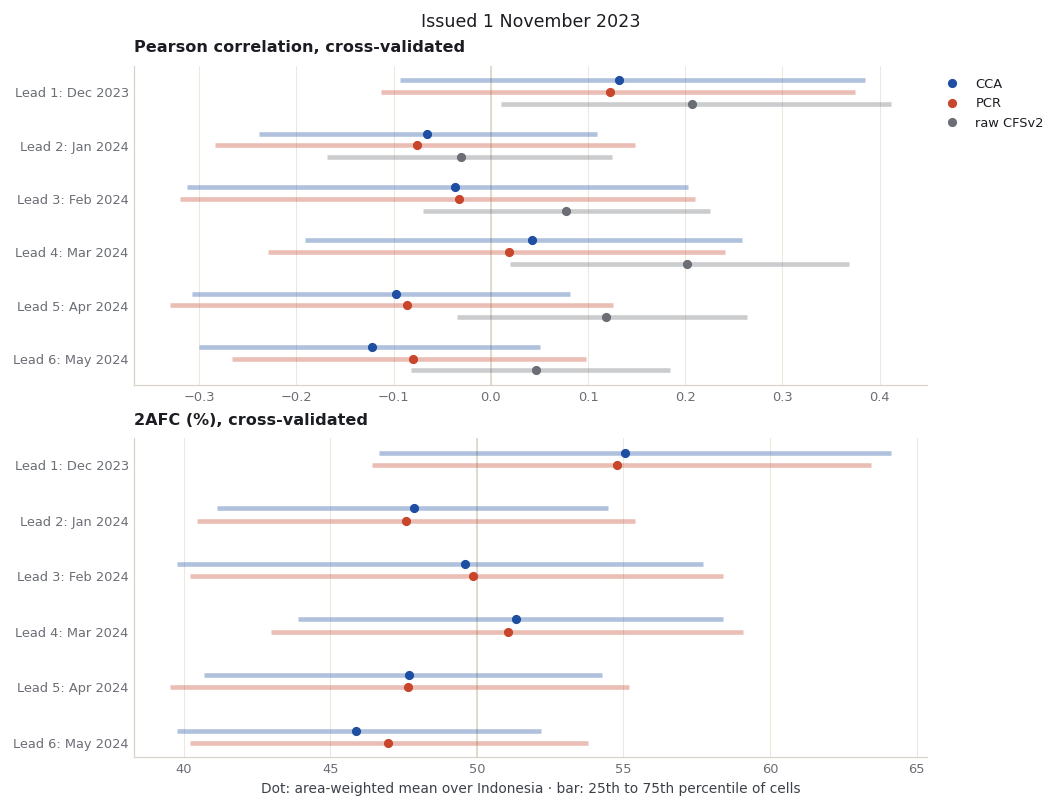

In [10]:
def quartiles(field):
    return np.nanpercentile(on_grid(field).where(cells).values, [25, 75])


series = {"CCA": figures.ACCENT, "PCR": figures.MARK, "raw CFSv2": figures.MUTED}
panels = [("Pearson", "pearson", "Pearson correlation, cross-validated", 0),
          ("2AFC (%)", "two_alternative_forced_choice", "2AFC (%), cross-validated", 50)]
fig, axes = plt.subplots(len(panels), 1, figsize=(figures.MAP_WIDTH, 7.2), layout="constrained")
for ax, (column, metric, title, reference) in zip(axes, panels):
    ax.axvline(reference, color=figures.LINE, linewidth=1)
    for k, (method, colour) in enumerate(series.items()):
        if method == "raw CFSv2" and metric != "pearson":
            continue
        offset = (k - 1) * 0.22
        for lead in leads:
            field = raw_pearson[lead] if method == "raw CFSv2" else results["issue", lead, method]["skill"][metric]
            low, high = quartiles(field)
            ax.plot([low, high], [lead + offset] * 2, color=colour, linewidth=3, alpha=.35, solid_capstyle="butt")
            ax.plot(skill_by_lead.loc[(lead, method), column], lead + offset, "o", color=colour, markersize=5,
                    label=method if lead == 1 else None)
    ax.set_yticks(leads, [f"Lead {lead}: {label[lead]}" for lead in leads])
    ax.invert_yaxis()
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
axes[-1].set_xlabel("Dot: area-weighted mean over Indonesia · bar: 25th to 75th percentile of cells")
fig.suptitle("Issued 1 November 2023")
assets = repo / "docs/assets/monthly-2023"
assets.mkdir(parents=True, exist_ok=True)
fig.savefig(assets / "skill-by-lead.png")
plt.show()

Where the skill sits matters as much as how much there is. The maps show the
cross-validated CCA correlation at each lead, in one column from lead 1 (top) to
lead 6 (bottom).

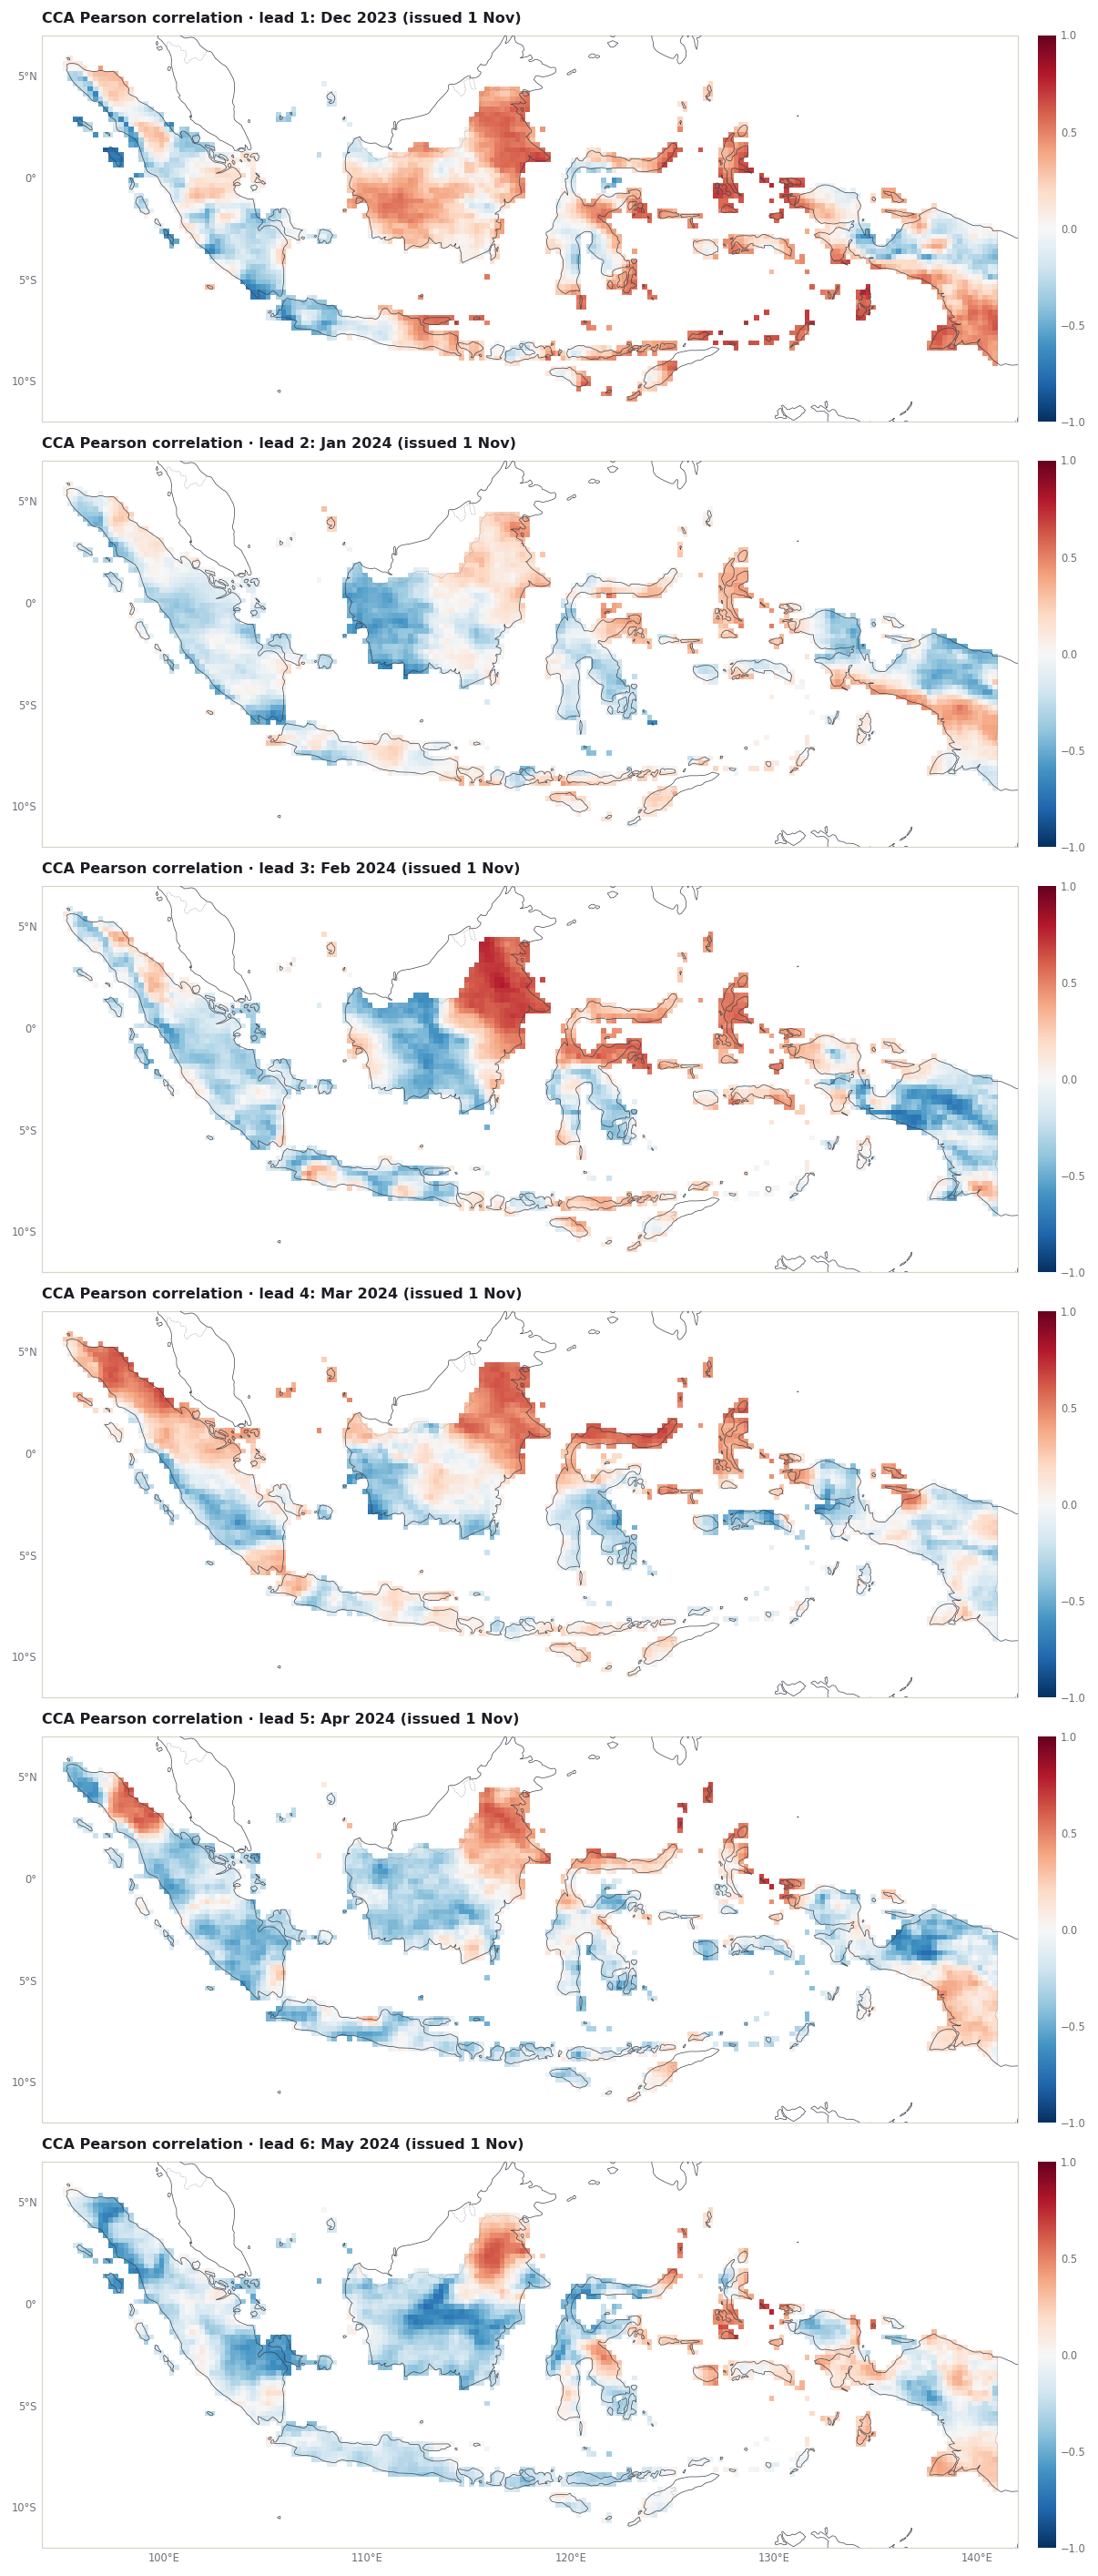

In [11]:
predictand_box = figures.extent_of(predictand_extent)
fig, grid = figures.stacked([figures.map_height(predictand_box)] * len(leads))
for row, lead in enumerate(leads):
    ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == len(leads) - 1)
    field = results["issue", lead, "CCA"]["skill"].pearson
    image = figures.draw_field(ax, field.where(field > -999), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_title(f"CCA Pearson correlation · lead {lead}: {label[lead]} (issued 1 Nov)")
    figures.colorbar(fig, image, ax, "", ticks=[-1, -.5, 0, .5, 1])
fig.savefig(assets / "cca-pearson-by-lead.png")
plt.show()

## 6. Is it the lead or the month?

The same CCA settings, now for one target, **November 2023**, forecast from
starts one to six months before it (1 October back to 1 May). Here
the target is fixed and only the lead changes. Side by side with section 5, at
each lead: if the two lines fall together, skill is mostly lost with lead time;
if they part, the target month matters as much as how far ahead it is.

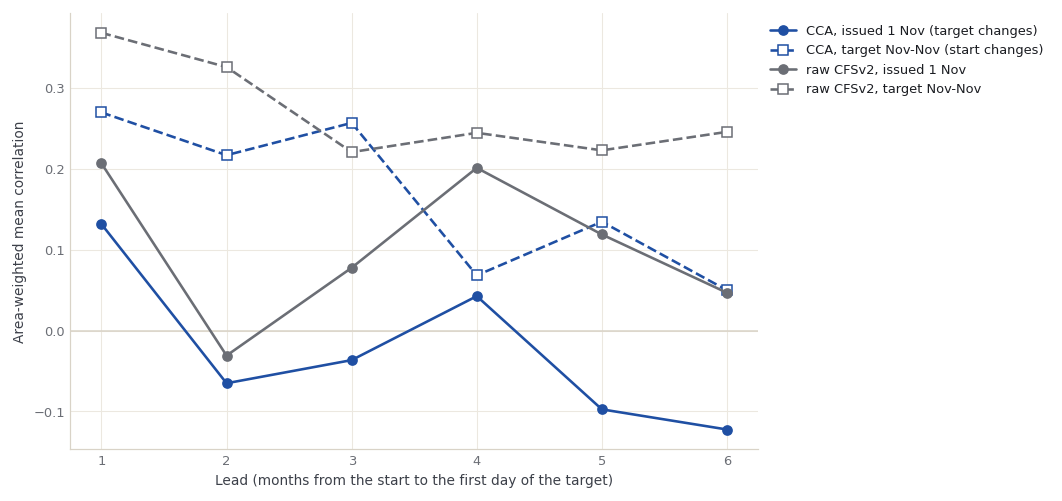

,start,target,CCA Pearson,raw CFSv2 Pearson,CCA 2AFC (%),"CCA Pearson, issued 1 Nov","raw CFSv2 Pearson, issued 1 Nov"
lead,,,,,,,
1,2023-10-01,Nov-Nov,0.270,0.369,58.752,0.132,0.207
2,2023-09-01,Nov-Nov,0.217,0.326,57.811,-0.065,-0.031
3,2023-08-01,Nov-Nov,0.257,0.221,59.339,-0.037,0.078
4,2023-07-01,Nov-Nov,0.068,0.245,53.093,0.043,0.201
5,2023-06-01,Nov-Nov,0.135,0.223,55.006,-0.097,0.119
6,2023-05-01,Nov-Nov,0.050,0.246,52.205,-0.122,0.047


In [12]:
rows = []
for lead in leads:
    d = inputs["fixed", lead]
    rows.append({"lead": lead, "start": fixed_starts[lead].date().isoformat(), "target": d["name"],
                 "CCA Pearson": area_mean(results["fixed", lead, "CCA"]["skill"].pearson),
                 "raw CFSv2 Pearson": area_mean(raw_correlation(d)),
                 "CCA 2AFC (%)": area_mean(results["fixed", lead, "CCA"]["skill"].two_alternative_forced_choice)})
same_target = pd.DataFrame(rows).set_index("lead")
same_target["CCA Pearson, issued 1 Nov"] = [skill_by_lead.loc[(lead, "CCA"), "Pearson"] for lead in leads]
same_target["raw CFSv2 Pearson, issued 1 Nov"] = [skill_by_lead.loc[(lead, "raw CFSv2"), "Pearson"] for lead in leads]

fig, ax = plt.subplots(figsize=(figures.MAP_WIDTH, 4.4), layout="constrained")
ax.axhline(0, color=figures.LINE, linewidth=1)
for column, colour, style, name in [("CCA Pearson, issued 1 Nov", figures.ACCENT, "-o", "CCA, issued 1 Nov (target changes)"),
                                    ("CCA Pearson", figures.ACCENT, "--s", f"CCA, target {fixed_target} (start changes)"),
                                    ("raw CFSv2 Pearson, issued 1 Nov", figures.MUTED, "-o", "raw CFSv2, issued 1 Nov"),
                                    ("raw CFSv2 Pearson", figures.MUTED, "--s", f"raw CFSv2, target {fixed_target}")]:
    ax.plot(leads, same_target[column], style, color=colour, label=name, markerfacecolor="white" if "--" in style else colour)
ax.set_xticks(leads, [f"{lead}" for lead in leads])
ax.set_xlabel("Lead (months from the start to the first day of the target)")
ax.set_ylabel("Area-weighted mean correlation")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.savefig(assets / "same-target-vs-issue.png")
plt.show()
same_target.round(3)

## 7. The forecasts as issued, and what happened

Each lead's forecast is checked against its own target: December
2023 to May 2024. The
categories are defined as in [chapter 5](../learn/05-probabilistic-forecasts.ipynb):
at each cell, below normal is under the 33rd percentile of that target's
1991-2020 values and above normal over the 67th (NumPy's `hazen` rule, which
reproduces CPT's own probabilities, as chapter 5 shows).

In [13]:
CATS = ["below normal", "near normal", "above normal"]
observed, reference_rows = {}, []
for lead in leads:
    d = inputs["issue", lead]
    obs, _ = observed_cells(d["F"][0])
    obs = obs.isel(T=0, drop=True).drop_vars(["Ti", "Tf"], errors="ignore").where(cells)
    Yl = d["Yl"]
    q = np.quantile(Yl.transpose("T", "Y", "X").values, [0.33, 0.67], axis=0, method="hazen")
    lower = xr.DataArray(q[0], coords={"Y": Yl["Y"], "X": Yl["X"]}, dims=("Y", "X")).where(cells)
    upper = lower.copy(data=q[1]).where(cells)
    category = xr.where(obs < lower, 0, xr.where(obs > upper, 2, 1)).where(cells & obs.notnull())
    mean = Yl.mean("T").where(cells)
    area = weights.where(category.notnull(), 0)
    shares = {name: float(area.where(category == k, 0).sum() / area.sum() * 100) for k, name in enumerate(CATS)}
    observed[lead] = dict(total=obs, mean=mean, category=category, shares=shares)
    reference_rows.append({"lead": lead, "target": label[lead],
                           "observed mean (mm)": float(obs.weighted(weights).mean()),
                           "1991-2020 mean (mm)": float(mean.weighted(weights).mean()),
                           **{f"observed {name} (% of area)": v for name, v in shares.items()},
                           "reference hit rate (%)": max(shares.values()),
                           "reference category": max(shares, key=shares.get)})
targets_2023 = pd.DataFrame(reference_rows).set_index("lead")
targets_2023.round(1)

,target,observed mean (mm),1991-2020 mean (mm),observed below normal (% of area),observed near normal (% of area),observed above normal (% of area),reference hit rate (%),reference category
lead,,,,,,,,
1,Dec 2023,254.6,294.4,52.8,30.9,16.3,52.8,below normal
2,Jan 2024,306.7,276.3,24.1,32.2,43.7,43.7,above normal
3,Feb 2024,241.8,250.4,37.1,33.8,29.0,37.1,below normal
4,Mar 2024,293.2,277.2,27.5,32.8,39.7,39.7,above normal
5,Apr 2024,311.9,269.4,18.1,28.0,53.9,53.9,above normal
6,May 2024,294.0,235.2,13.8,23.0,63.2,63.2,above normal


Observed category at each lead's target, in one column from lead 1 (top) to
lead 6 (bottom).

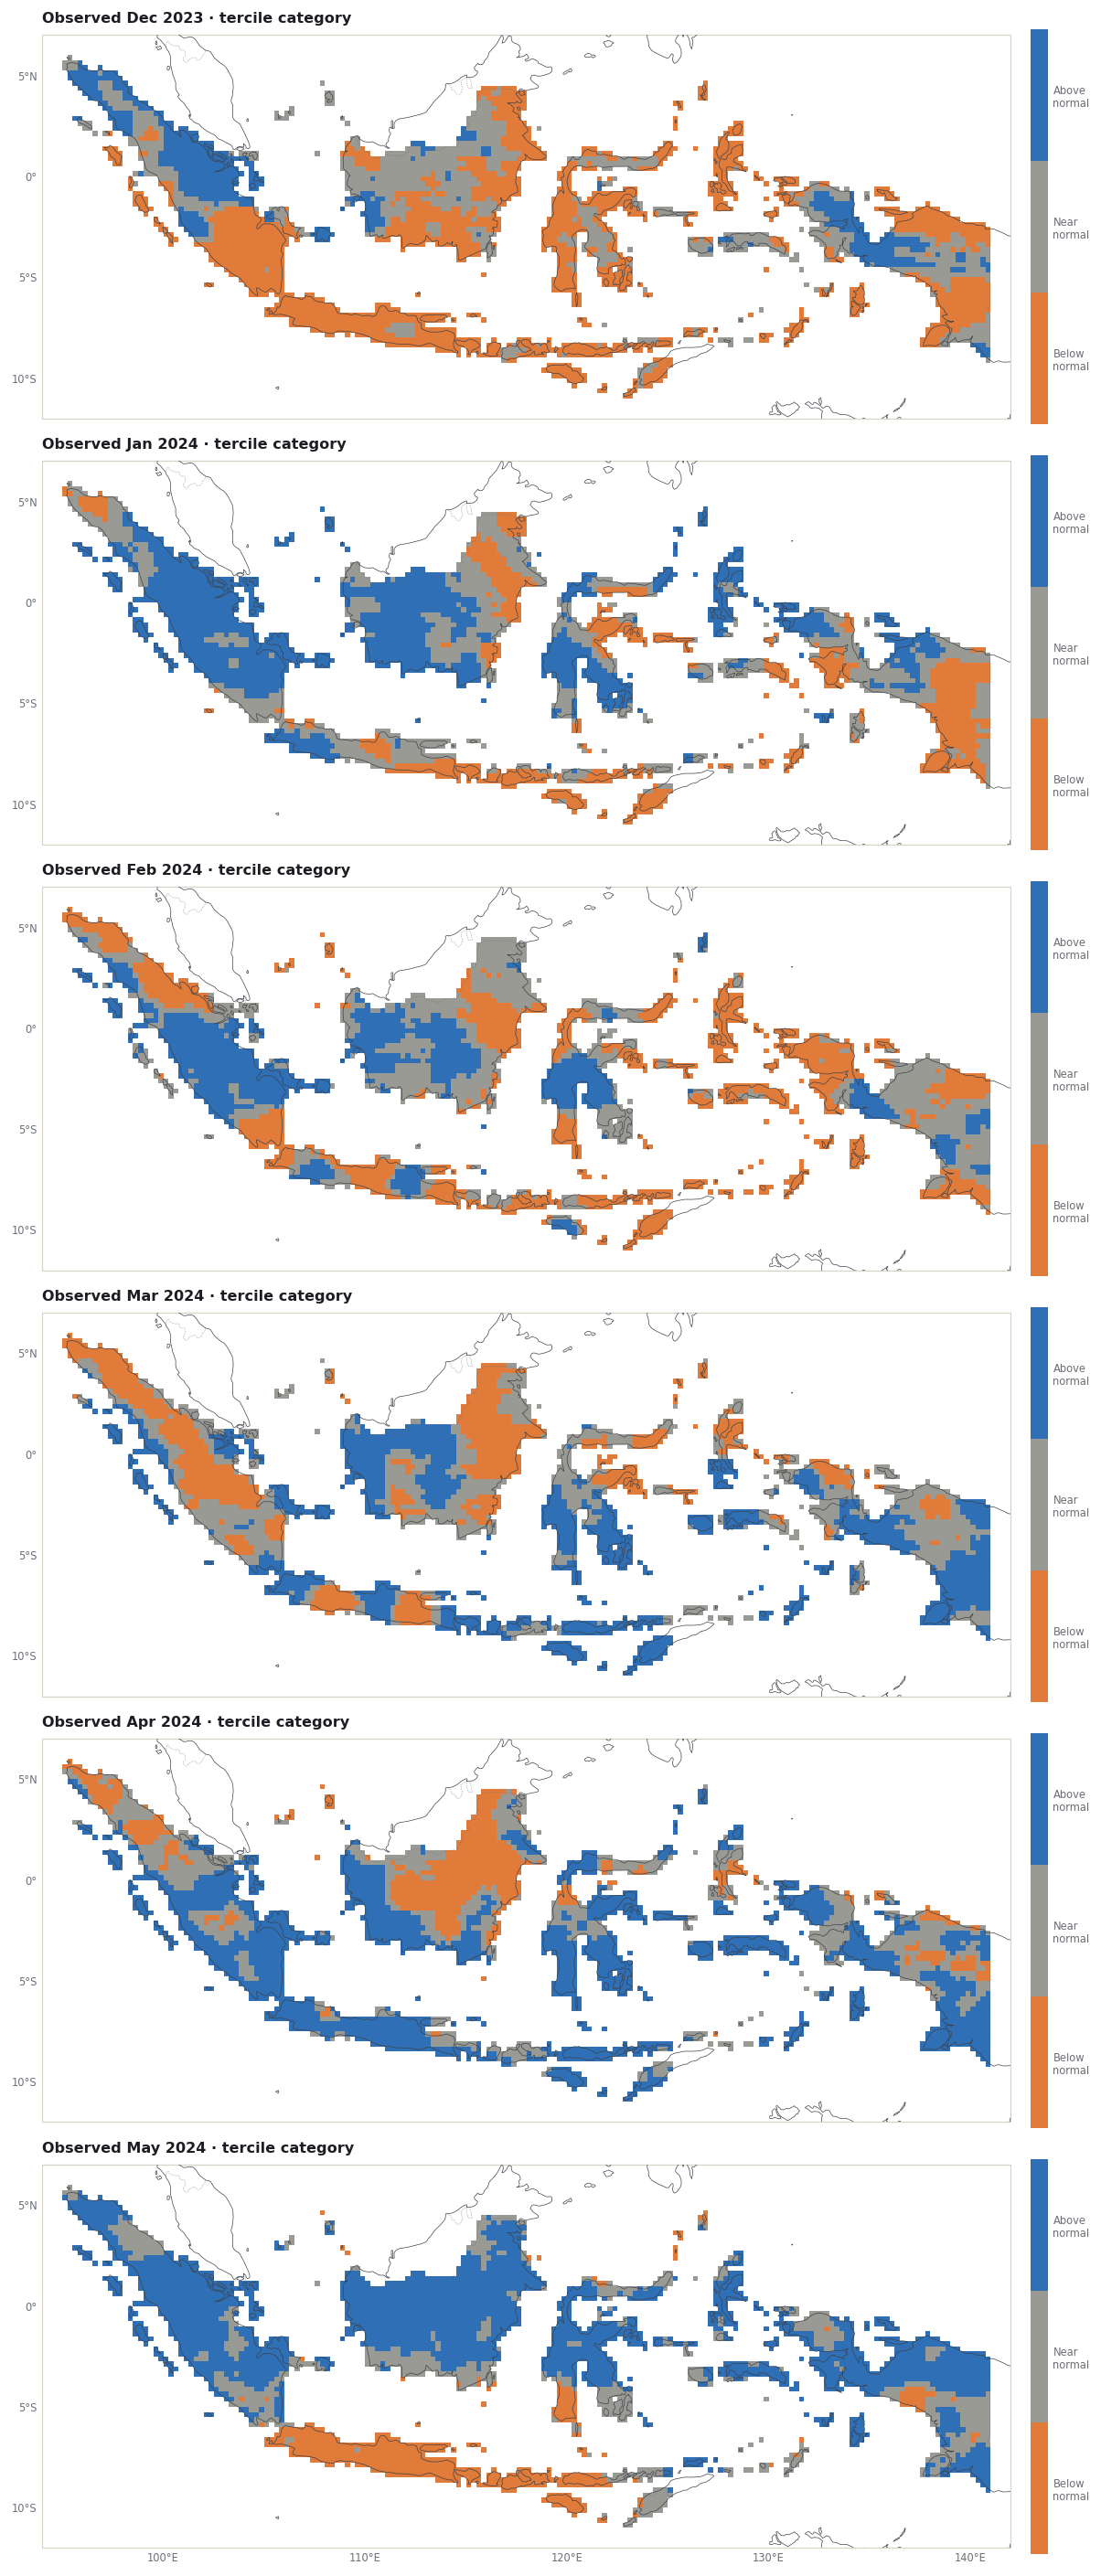

In [14]:
def category_bar(fig, image, ax):
    # a colour bar with the three category names, so every map in a column has the same width
    bar = figures.colorbar(fig, image, ax, "", ticks=[0, 1, 2])
    bar.ax.set_yticklabels(["Below\nnormal", "Near\nnormal", "Above\nnormal"])
    return bar


fig, grid = figures.stacked([figures.map_height(predictand_box)] * len(leads))
for row, lead in enumerate(leads):
    ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == len(leads) - 1)
    category_bar(fig, figures.category_map(ax, observed[lead]["category"]), ax)
    ax.set_title(f"Observed {label[lead]} · tercile category")
fig.savefig(assets / "observed-by-lead.png")
plt.show()

Now the forecasts. Each lead gives a probability for each category at each cell.
Three ways to score them against what happened, each area-weighted over the cells:

- **Hit rate**: share of area where the most likely category was the one observed.
  Always forecasting one category would hit the area where that category happened;
  the **reference hit rate** above is the best such constant guess, chosen with
  hindsight.
- **RPSS**: ranked probability skill score of this one target's probabilities
  against climatological odds (33/34/33%). Above 0 means closer to what happened
  than climatology; it is one outcome, not a skill estimate.
- **RMSE**: error of the deterministic forecast in mm.

The table also gives the share of the area where each category was the most likely
one, to see whether a hit rate comes from placing categories well or from favouring
the category that happened almost everywhere.

In [15]:
def rps(probability, category):
    cumulative = probability.cumsum("C") / 100
    outcome = xr.concat([(category <= k).astype(float) for k in range(3)], dim="C").assign_coords(C=probability["C"])
    return ((cumulative - outcome) ** 2).isel(C=slice(0, 2)).sum("C")


clim = xr.DataArray([33.0, 34.0, 33.0], dims="C")
forecast_rows, most_likely, deterministic = [], {}, {}
for lead in leads:
    o = observed[lead]
    valid = o["category"].notnull()
    for MOS in ["CCA", "PCR"]:
        f = results["issue", lead, MOS]["fcsts"]
        p = on_grid(f.probabilistic.isel(T=0))
        clim_p = clim.assign_coords(C=p["C"]).broadcast_like(p)
        m = p.fillna(-1).argmax("C").where(p.notnull().all("C") & valid)
        most_likely[lead, MOS] = (m, p.max("C"))
        w = weights.where(m.notnull(), 0)                       # cells with both a forecast and an observation
        det = on_grid(f.deterministic.isel(T=0)).where(cells)
        deterministic[lead, MOS] = det
        forecast_rows.append({"lead": lead, "target": label[lead], "method": MOS,
                              "hit rate (%)": float(w.where(m == o["category"], 0).sum() / w.sum() * 100),
                              "RPSS": float(1 - rps(p, o["category"]).weighted(w).mean() / rps(clim_p, o["category"]).weighted(w).mean()),
                              "RMSE (mm)": float(np.sqrt(((det - o["total"]) ** 2).weighted(w).mean())),
                              "mean forecast (mm)": float(det.weighted(w).mean()),
                              "observed mean (mm)": float(o["total"].weighted(w).mean()),
                              **{f"area forecast {name} (%)": float(w.where(m == k, 0).sum() / w.sum() * 100)
                                 for k, name in enumerate(["below", "near", "above"])}})
forecast_2023 = pd.DataFrame(forecast_rows).set_index(["lead", "method"]).sort_index()
forecast_2023.round(2)

target  hit rate (%)  RPSS  RMSE (mm)  mean forecast (mm)  \
lead method                                                                
1    CCA     Dec 2023         53.51  0.21      79.14              262.60   
     PCR     Dec 2023         54.69  0.21      79.08              258.69   
2    CCA     Jan 2024         38.87  0.02     103.31              253.99   
     PCR     Jan 2024         38.89 -0.00     107.27              249.25   
3    CCA     Feb 2024         52.33  0.15      67.41              228.85   
     PCR     Feb 2024         49.71  0.12      70.91              230.05   
4    CCA     Mar 2024         38.71  0.04      91.42              253.96   
     PCR     Mar 2024         37.16  0.03      91.54              254.03   
5    CCA     Apr 2024         37.31  0.00     105.03              257.83   
     PCR     Apr 2024         36.50 -0.01     105.90              259.02   
6    CCA     May 2024         25.78 -0.15     129.45              219.26   
     PCR     May 2024         31.56 -0.19     138.20              213.66   

             observed mean (mm)  area forecast below (%)  \
lead method                                                
1    CCA                 254.64                    74.46   
     PCR                 254.64                    72.86   
2    CCA                 306.74                    74.67   
     PCR                 306.74                    72.31   
3    CCA                 241.80                    63.51   
     PCR                 241.80                    59.24   
4    CCA                 293.25                    69.82   
     PCR                 293.25                    71.56   
5    CCA                 311.91                    56.48   
     PCR                 311.91                    55.64   
6    CCA                 293.97                    53.46   
     PCR                 293.97                    53.47   

             area forecast near (%)  area forecast above (%)  
lead method                                                   
1    CCA                       1.24                    24.30  
     PCR                       2.13                    25.01  
2    CCA                       6.87                    18.46  
     PCR                       1.88                    25.81  
3    CCA                       5.70                    30.78  
     PCR                       5.33                    35.43  
4    CCA                       6.63                    23.56  
     PCR                       5.17                    23.27  
5    CCA                      10.70                    32.82  
     PCR                       6.69                    37.67  
6    CCA                       5.28                    41.25  
     PCR                       2.81                    43.72

The CCA forecasts' most likely category at each lead, in one column. Compare each
map with the same lead in the observed column above.

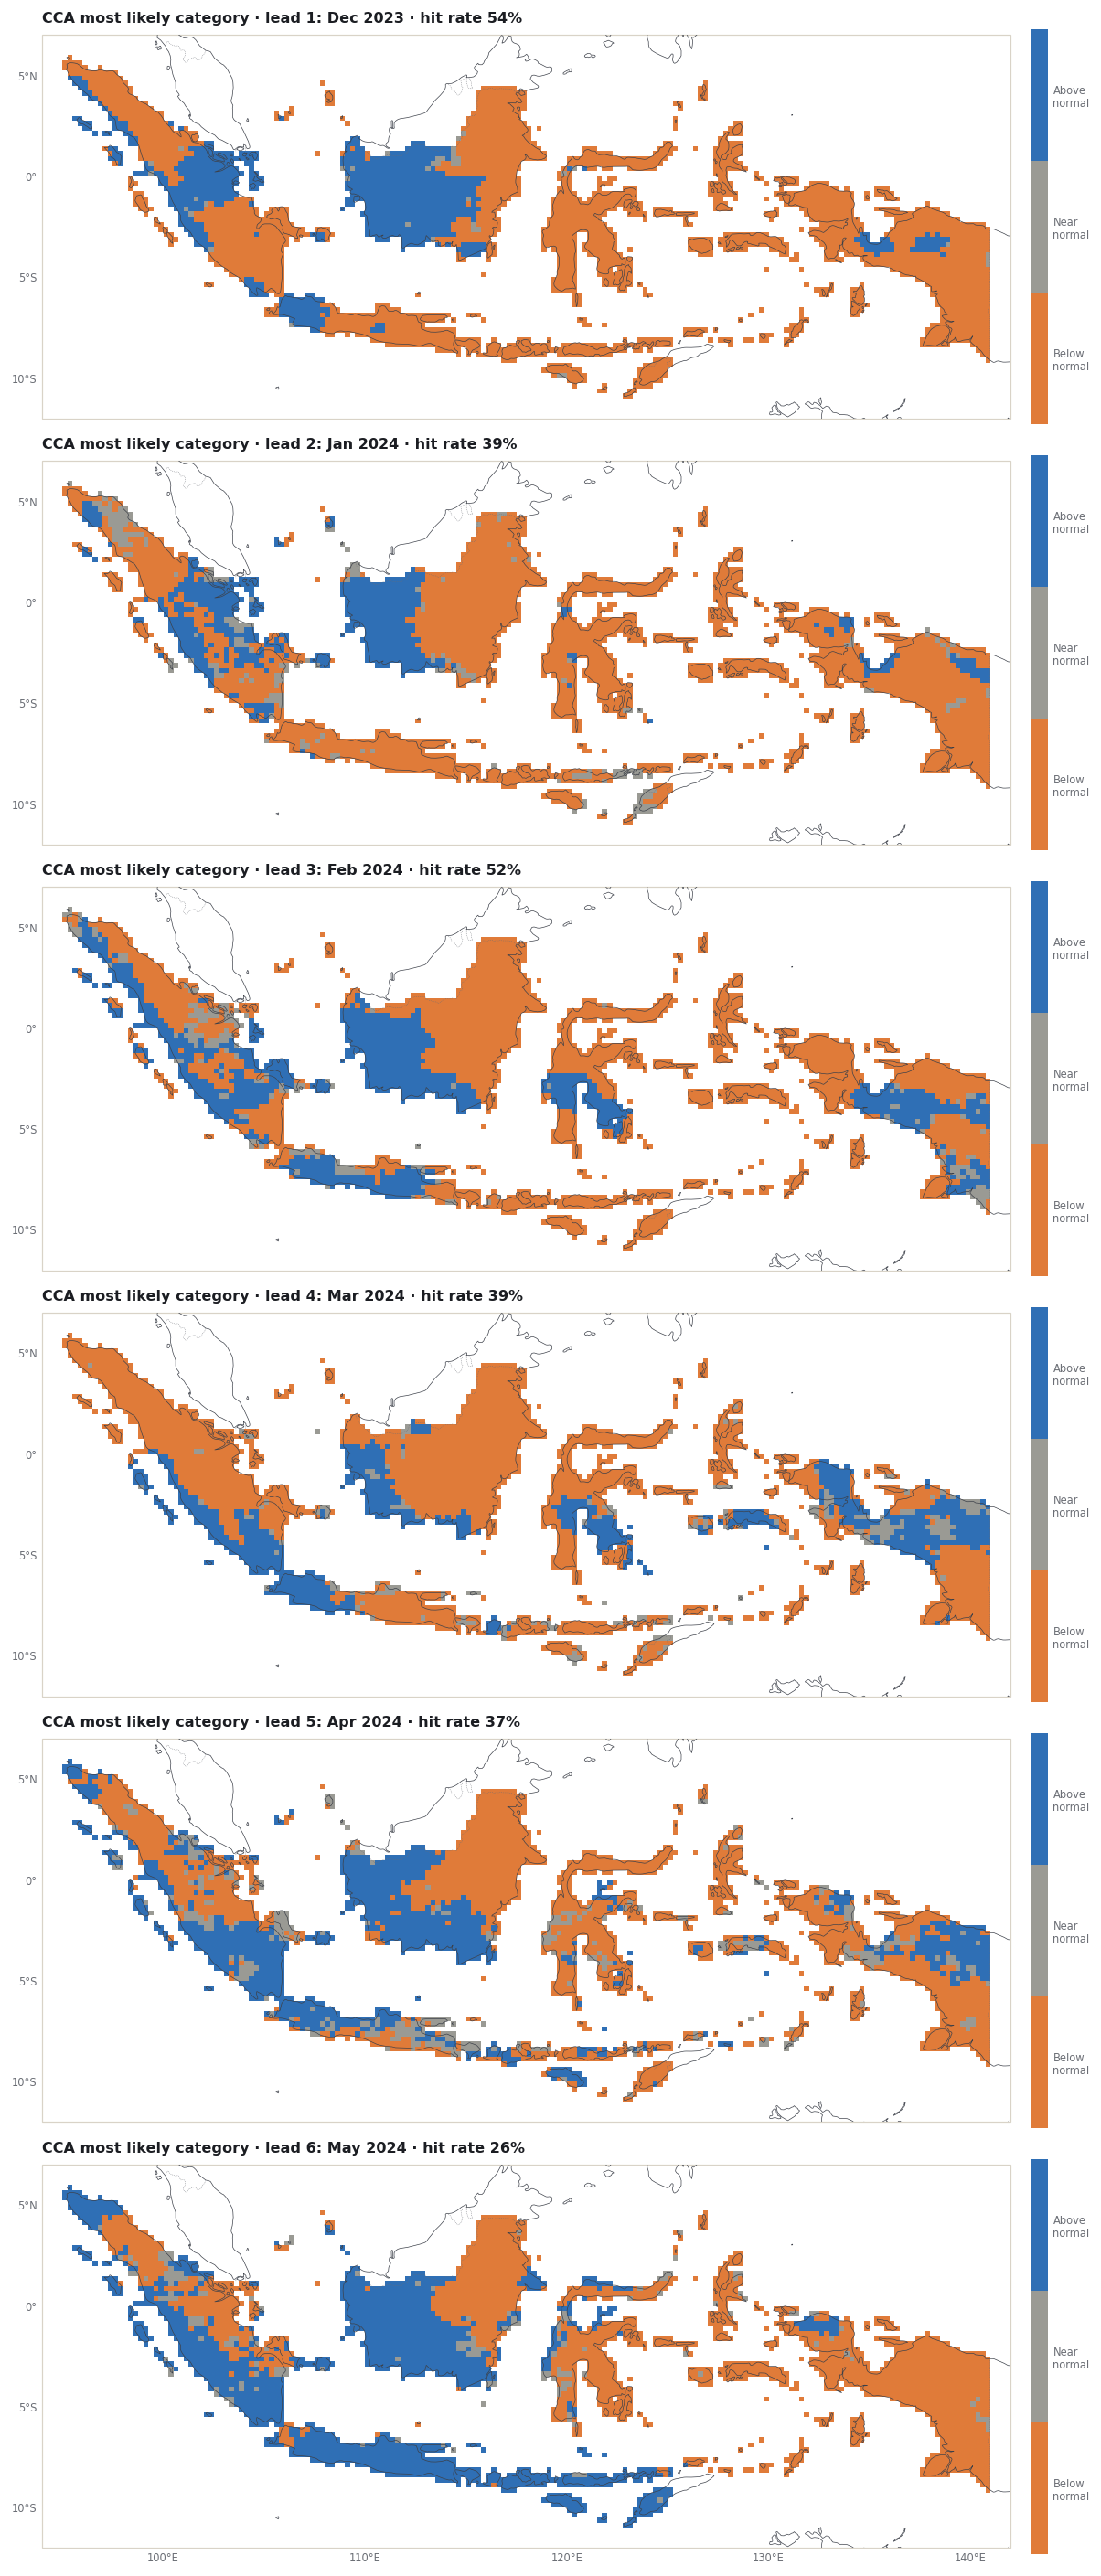

In [16]:
fig, grid = figures.stacked([figures.map_height(predictand_box)] * len(leads))
for row, lead in enumerate(leads):
    ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == len(leads) - 1)
    category_bar(fig, figures.category_map(ax, most_likely[lead, "CCA"][0]), ax)
    hit = forecast_2023.loc[(lead, "CCA"), "hit rate (%)"]
    ax.set_title(f"CCA most likely category · lead {lead}: {label[lead]} · hit rate {hit:.0f}%")
fig.savefig(assets / "cca-category-by-lead.png")
plt.show()

## 8. Save the results

The story page quotes these tables and draws its interactive views from the JSON
file written at the end.

In [17]:
data_dir = repo / "docs/data/monthly-2023"
data_dir.mkdir(parents=True, exist_ok=True)
skill_by_lead.round(4).to_csv(data_dir / "skill-by-lead.csv")
forecast_2023.round(4).to_csv(data_dir / "issued-2023-11-forecasts.csv")
targets_2023.round(4).to_csv(data_dir / "issued-2023-11-observed.csv")
same_target.round(4).to_csv(data_dir / "same-target-skill.csv")
if "comparison" in globals():
    comparison.round(4).to_csv(data_dir / "seasonal-vs-monthly.csv")
summary = {"issued": issue.date().isoformat(), "leads_months": leads,
           "targets": {lead: {"pycpt_target": targets[lead], "label": label[lead],
                               "first_day": str(inputs["issue", lead]["F"][0]["Ti"].values[0])[:10],
                               "last_day": str(inputs["issue", lead]["F"][0]["Tf"].values[0])[:10]} for lead in leads},
           "same_target": {"target": fixed_target, "starts": {lead: s.date().isoformat() for lead, s in fixed_starts.items()}},
           "training_target_years": [training_years[0], training_years[-1]], "cells": int(cells.sum()),
           "settings": {k: str(v) for k, v in cpt_args.items()},
           "fit_seconds": {f"{k[0]}-{k[1]}-{k[2]}": round(r["seconds"], 1) for k, r in results.items()}}
(data_dir / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
maps = xr.Dataset()
for lead in leads:
    maps[f"observed_lead{lead}"] = observed[lead]["total"].reset_coords(drop=True)
    maps[f"observed_category_lead{lead}"] = observed[lead]["category"].reset_coords(drop=True)
    for MOS in ["CCA", "PCR"]:
        maps[f"{MOS.lower()}_pearson_lead{lead}"] = on_grid(results["issue", lead, MOS]["skill"].pearson).reset_coords(drop=True)
        maps[f"{MOS.lower()}_forecast_lead{lead}"] = deterministic[lead, MOS].reset_coords(drop=True)
        maps[f"{MOS.lower()}_most_likely_lead{lead}"] = most_likely[lead, MOS][0].reset_coords(drop=True)
save_netcdf(maps, data_dir / "monthly-2023-maps.nc", overwrite=True,
            metadata={"note": "CFSv2 started 1 November 2023, leads 1-6 months (Dec 2023 to May 2024), CCA and PCR; categories 0 below, 1 near, 2 above normal"})
for f in sorted(data_dir.iterdir()) + sorted(assets.iterdir()):
    print(f"{f.relative_to(repo)}  ({f.stat().st_size / 1000:.0f} kB)")

docs/data/monthly-2023/issued-2023-11-forecasts.csv  (1 kB)
docs/data/monthly-2023/issued-2023-11-observed.csv  (1 kB)
docs/data/monthly-2023/monthly-2023-maps.nc  (1163 kB)
docs/data/monthly-2023/november-2023-forecasts.csv  (1 kB)
docs/data/monthly-2023/same-target-skill.csv  (0 kB)
docs/data/monthly-2023/skill-by-lead.csv  (1 kB)
docs/data/monthly-2023/summary.json  (2 kB)
docs/assets/monthly-2023/cca-category-by-lead.png  (1115 kB)
docs/assets/monthly-2023/cca-pearson-by-lead.png  (1242 kB)
docs/assets/monthly-2023/interactive-data.json  (1233 kB)
docs/assets/monthly-2023/observed-2023.png  (390 kB)
docs/assets/monthly-2023/observed-by-lead.png  (1096 kB)
docs/assets/monthly-2023/same-target-vs-issue.png  (119 kB)
docs/assets/monthly-2023/skill-by-lead.png  (110 kB)


The story page's interactive maps and charts read one compact JSON file: every field
is stored only at the Indonesian cells, in the order of a shared cell list.

In [18]:
def records(frame):
    return [{k: (None if isinstance(v, float) and not np.isfinite(v) else v) for k, v in row.items()}
            for row in frame.to_dict(orient="records")]


yy, xx = np.nonzero(cells.transpose("Y", "X").values)
pack = lambda a, d=1: [None if not np.isfinite(v) else round(float(v), d)
                       for v in np.asarray(a.transpose("Y", "X").values, dtype=float)[yy, xx]]
values = np.concatenate([observed[lead]["total"].values.ravel() for lead in leads]
                        + [deterministic[k].values.ravel() for k in deterministic])
target_info = [{"lead": lead, "label": label[lead], "pycpt": targets[lead],
                "start": str(inputs["issue", lead]["F"][0]["Ti"].values[0])[:10],
                "end": str(pd.Timestamp(inputs["issue", lead]["F"][0]["Tf"].values[0]) + pd.Timedelta(days=1))[:10]} for lead in leads]
interactive = {
    "grid": {"lat": [round(float(v), 3) for v in cells["Y"].values[yy]], "lon": [round(float(v), 3) for v in cells["X"].values[xx]],
             "step": 0.25},
    "kind": "month", "issue": {"date": issue.date().isoformat(), "label": "1 Nov 2023"},
    "leads": leads, "methods": ["CCA", "PCR"], "rawName": "raw CFSv2", "unit": "mm",
    "training": "1991-2020", "sample": "the 30 training years, 1991-2020",
    "leadNames": [f"Lead {lead} · {label[lead]}" for lead in leads],
    "targets": target_info,
    "rainMax": float(np.ceil(np.nanpercentile(values, 99) / 100) * 100),
    "skill": {m: {str(lead): {"pearson": pack(on_grid(results["issue", lead, m]["skill"].pearson), 3),
                              "twoafc": pack(on_grid(results["issue", lead, m]["skill"].two_alternative_forced_choice), 1)}
                  for lead in leads} for m in ["CCA", "PCR"]},
    "raw": {str(lead): pack(raw_pearson[lead], 3) for lead in leads},
    "skillTable": records(skill_by_lead.reset_index().round(4)),
    "observed": {str(lead): {"total": pack(observed[lead]["total"]), "mean": pack(observed[lead]["mean"]),
                             "category": pack(observed[lead]["category"], 0)} for lead in leads},
    "forecasts": {str(lead): {m: {"total": pack(deterministic[lead, m]),
                                  "category": pack(most_likely[lead, m][0], 0),
                                  "probability": pack(most_likely[lead, m][1].where(cells), 0)}
                              for m in ["CCA", "PCR"]} for lead in leads},
    "scores2023": records(forecast_2023.reset_index().round(3)),
    "references": records(targets_2023.reset_index().round(3)),
    "sameTarget": {"target": "November 2023", "rows": records(same_target.reset_index().round(4))},
}
if "comparison" in globals():
    interactive["comparison"] = records(comparison.reset_index().round(4))
(assets / "interactive-data.json").write_text(json.dumps(interactive, separators=(",", ":"), allow_nan=False) + "\n")
print(f"{assets.relative_to(repo)}/interactive-data.json: {(assets / 'interactive-data.json').stat().st_size / 1000:.0f} kB, "
      f"{len(yy)} cells, colour scale up to {interactive['rainMax']:.0f} mm")

docs/assets/monthly-2023/interactive-data.json: 1514 kB, 3240 cells, colour scale up to 600 mm


## References {.unnumbered .reference-section}

1. IRI. *PyCPT 2.10.4 source: `pycpt/src/pycpt/notebook.py`* (`setup`, `download_data`, `summarize_available_years`, `evaluate_models` and the plotting functions). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/pycpt/notebook.py>
2. IRI. *PyCPT 2.10.4 source: `cptdl`* (data catalog, `leads_from_target`, `evaluate_url`, `download`, `simple_download`). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/tree/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/cptdl>
3. IRI. *CPT 17.8.3 source code archive*. Columbia University Academic Commons. <https://doi.org/10.7916/fdp6-v391>
4. CPT+. *Forecast Probabilities* (CPT help). <https://cptplus.org/Help/Tools_Forecast_Probs.html> Same page name as on the former cpthelp.iri.columbia.edu, which did not resolve when checked on 10 November 2026.
5. IRI Data Library. *NMME NCEP-CFSv2 hindcasts, PENTAD_SAMPLES_FULL, precipitation*. <https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/> Browsing Data Library pages requires signing in (checked 10 November 2026); PyCPT's data requests in this tutorial succeeded without a key.
6. Saha, S., Moorthi, S., Wu, X., et al. (2014). The NCEP Climate Forecast System Version 2. *Journal of Climate*, 27(6), 2185-2208. <https://doi.org/10.1175/JCLI-D-12-00823.1>
7. Climate Hazards Center, UC Santa Barbara. *CHIRPS: Rainfall Estimates from Rain Gauge and Satellite Observations* (CHIRPS version 3.0 page). <https://www.chc.ucsb.edu/data/chirps3>
8. Funk, C., Peterson, P., Landsfeld, M., et al. (2014). *A quasi-global precipitation time series for drought monitoring*. U.S. Geological Survey Data Series 832. <https://doi.org/10.3133/ds832>
9. Natural Earth. *Admin 0: Countries*, 1:10m cultural vectors. <https://www.naturalearthdata.com/downloads/10m-cultural-vectors/10m-admin-0-countries/>
10. Shapely. *shapely.contains_xy*. <https://shapely.readthedocs.io/en/stable/reference/shapely.contains_xy.html>
11. NumPy. *numpy.quantile* (NumPy manual). <https://numpy.org/doc/stable/reference/generated/numpy.quantile.html>
12. Mason, S. J., and Weigel, A. P. (2009). A generic forecast verification framework for administrative purposes. *Monthly Weather Review*, 137(1), 331-349. <https://doi.org/10.1175/2008MWR2553.1>
13. Epstein, E. S. (1969). A scoring system for probability forecasts of ranked categories. *Journal of Applied Meteorology*, 8(6), 985-987. <https://doi.org/10.1175/1520-0450(1969)008%3C0985:ASSFPF%3E2.0.CO;2>
14. Barnston, A. G., and van den Dool, H. M. (1993). A degeneracy in cross-validated skill in regression-based forecasts. *Journal of Climate*, 6(5), 963-977. <https://doi.org/10.1175/1520-0442(1993)006%3C0963:ADICVS%3E2.0.CO;2>
15. SciTools. *Cartopy* (documentation). <https://scitools.org.uk/cartopy/docs/latest/>